Paths and reusable definitions were refactored. Stored outputs below are historical, not a fresh execution. See `docs/WORKFLOW.md` at the repository root before rerunning; several stages overwrite results or append Optuna trials.


In [ ]:
# Locate this checkout from the repository root or any notebook subdirectory.
from pathlib import Path
import sys

_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p / "src" / "steam_recommender" / "paths.py").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside the repository checkout.")
sys.path.insert(0, str(_root / "src"))
from steam_recommender import paths as _paths
if Path(_paths.__file__).resolve() != (_root / "src/steam_recommender/paths.py").resolve():
    raise RuntimeError("A different checkout is cached; restart the kernel.")
from steam_recommender.paths import project_root, project_path


# old

In [1]:
# =========================
# FINAL TEST FIGURES
# =========================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =========================
# PATHS
# =========================


final_results_dir = os.path.join(str(project_path("results/final")))
figures_dir = os.path.join(str(project_path("results/figures")))
test_figures_dir = os.path.join(figures_dir, "test")

os.makedirs(test_figures_dir, exist_ok=True)

test_metrics_path = os.path.join(
    final_results_dir,
    "test_metrics_by_seed.csv"
)

test_summary_path = os.path.join(
    final_results_dir,
    "test_metrics_summary.csv"
)

pretty_test_summary_path = os.path.join(
    final_results_dir,
    "test_metrics_summary_pretty.csv"
)


# =========================
# LOAD DATA
# =========================

test_metrics_df = pd.read_csv(test_metrics_path)

display(test_metrics_df)

print("test_metrics_df:", test_metrics_df.shape)

,model,function,function_label,seed,factors,iterations,alpha,beta,regularization,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,ALS-linear,linear,liniowa,0.0,80.0,30.0,9.948124e-07,NaN,0.003588,0.184005,0.264033,0.330002,0.117960,-0.212504,0.789018,62944
1,ALS-linear,linear,liniowa,1.0,80.0,30.0,9.948124e-07,NaN,0.003588,0.183722,0.263528,0.329067,0.117308,-0.213088,0.780653,62944
2,ALS-linear,linear,liniowa,2.0,80.0,30.0,9.948124e-07,NaN,0.003588,0.184113,0.264080,0.329935,0.118613,-0.210822,0.790994,62944
3,ALS-linear,linear,liniowa,3.0,80.0,30.0,9.948124e-07,NaN,0.003588,0.184410,0.264631,0.330450,0.116873,-0.209020,0.776920,62944
4,ALS-linear,linear,liniowa,4.0,80.0,30.0,9.948124e-07,NaN,0.003588,0.184251,0.264578,0.330196,0.118178,-0.210772,0.789579,62944
5,ALS-log,log,logarytmiczna,0.0,24.0,30.0,5.713901e-04,NaN,0.130920,0.181097,0.301975,0.335580,0.076212,0.544026,0.608090,62944
6,ALS-log,log,logarytmiczna,1.0,24.0,30.0,5.713901e-04,NaN,0.130920,0.180883,0.301593,0.335383,0.076212,0.542595,0.582724,62944
7,ALS-log,log,logarytmiczna,2.0,24.0,30.0,5.713901e-04,NaN,0.130920,0.180843,0.301766,0.335344,0.075886,0.543848,0.576582,62944
8,ALS-log,log,logarytmiczna,3.0,24.0,30.0,5.713901e-04,NaN,0.130920,0.181001,0.301962,0.336079,0.076538,0.542305,0.612769,62944
9,ALS-log,log,logarytmiczna,4.0,24.0,30.0,5.713901e-04,NaN,0.130920,0.181012,0.301986,0.335678,0.075995,0.543838,0.601342,62944


test_metrics_df: (21, 16)


In [2]:
# =========================
# LABELS / COLORS / ORDER
# =========================

K = 10

function_order = [
    "popular",
    "linear",
    "log",
    "log_saturation",
    "log_inside_beta",
]

function_labels = {
    "popular": "popularność",
    "linear": "liniowa",
    "log": "logarytmiczna",
    "log_saturation": "logarytmiczna z saturacją",
    "log_inside_beta": "logarytmiczna z przesunięciem β",
}

function_colors = {
    "popular": "tab:gray",
    "linear": "tab:blue",
    "log": "tab:orange",
    "log_saturation": "tab:red",
    "log_inside_beta": "tab:green",
}

In [3]:
# =========================
# SUMMARY: MEAN ± STD
# =========================

metric_cols = [
    f"precision@{K}",
    f"recall@{K}",
    f"ndcg@{K}",
    f"coverage@{K}",
    f"delta_gap@{K}",
    f"diversity@{K}",
    "users_evaluated",
]

summary_rows = []

for (model_name, function_name), group in test_metrics_df.groupby(["model", "function"]):
    row = {
        "model": model_name,
        "function": function_name,
        "function_label": function_labels.get(function_name, function_name),
        "n_runs": group["seed"].notna().sum(),
    }

    for metric in metric_cols:
        row[f"{metric}_mean"] = group[metric].mean()
        row[f"{metric}_std"] = group[metric].std(ddof=1)

    summary_rows.append(row)

test_summary_df = pd.DataFrame(summary_rows)

test_summary_df["function_order"] = test_summary_df["function"].map(
    {name: i for i, name in enumerate(function_order)}
)

test_summary_df = (
    test_summary_df
    .sort_values("function_order")
    .drop(columns=["function_order"])
    .reset_index(drop=True)
)

test_summary_df.to_csv(test_summary_path, index=False)

display(test_summary_df)

print(f"Saved summary to: {test_summary_path}")

,model,function,function_label,n_runs,precision@10_mean,precision@10_std,recall@10_mean,recall@10_std,ndcg@10_mean,ndcg@10_std,coverage@10_mean,coverage@10_std,delta_gap@10_mean,delta_gap@10_std,diversity@10_mean,diversity@10_std,users_evaluated_mean,users_evaluated_std
0,Popular,popular,popularność,0,0.096519,NaN,0.178252,NaN,0.185480,NaN,0.008698,NaN,1.423258,NaN,NaN,NaN,62944.0,NaN
1,ALS-linear,linear,liniowa,5,0.184100,0.000260,0.264170,0.000452,0.329930,0.000523,0.117786,0.000694,-0.211241,0.001607,0.785433,0.006251,62944.0,0.0
2,ALS-log,log,logarytmiczna,5,0.180967,0.000103,0.301856,0.000173,0.335613,0.000295,0.076169,0.000250,0.543323,0.000807,0.596301,0.015880,62944.0,0.0
3,ALS-log-saturation,log_saturation,logarytmiczna z saturacją,5,0.180868,0.000166,0.301907,0.000302,0.335418,0.000484,0.076104,0.000172,0.544328,0.000893,0.594833,0.015152,62944.0,0.0
4,ALS-log-inside-beta,log_inside_beta,logarytmiczna z przesunięciem β,5,0.195639,0.000180,0.333795,0.000334,0.351690,0.000352,0.131333,0.000866,0.419129,0.002309,0.731420,0.017398,62944.0,0.0


Saved summary to: D:\Studiowe\Licencjat\modele\final_results\test_metrics_summary.csv


In [4]:
# =========================
# PRETTY TABLE: MEAN ± STD
# =========================

pretty_rows = []

for _, row in test_summary_df.iterrows():
    pretty_row = {
        "Model": row["function_label"],
    }

    for metric in metric_cols:
        mean = row[f"{metric}_mean"]
        std = row[f"{metric}_std"]

        if pd.isna(mean):
            pretty_row[metric] = "—"
        elif row["function"] == "popular":
            if metric == "users_evaluated":
                pretty_row[metric] = f"{mean:.0f}"
            else:
                pretty_row[metric] = f"{mean:.4f}"
        else:
            if metric == "users_evaluated":
                pretty_row[metric] = f"{mean:.0f} ± {std:.0f}"
            else:
                pretty_row[metric] = f"{mean:.4f} ± {std:.4f}"

    pretty_rows.append(pretty_row)

pretty_test_summary = pd.DataFrame(pretty_rows)

pretty_test_summary.to_csv(pretty_test_summary_path, index=False)

display(pretty_test_summary)

print(f"Saved pretty summary to: {pretty_test_summary_path}")

,Model,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,popularność,0.0965,0.1783,0.1855,0.0087,1.4233,—,62944
1,liniowa,0.1841 ± 0.0003,0.2642 ± 0.0005,0.3299 ± 0.0005,0.1178 ± 0.0007,-0.2112 ± 0.0016,0.7854 ± 0.0063,62944 ± 0
2,logarytmiczna,0.1810 ± 0.0001,0.3019 ± 0.0002,0.3356 ± 0.0003,0.0762 ± 0.0003,0.5433 ± 0.0008,0.5963 ± 0.0159,62944 ± 0
3,logarytmiczna z saturacją,0.1809 ± 0.0002,0.3019 ± 0.0003,0.3354 ± 0.0005,0.0761 ± 0.0002,0.5443 ± 0.0009,0.5948 ± 0.0152,62944 ± 0
4,logarytmiczna z przesunięciem β,0.1956 ± 0.0002,0.3338 ± 0.0003,0.3517 ± 0.0004,0.1313 ± 0.0009,0.4191 ± 0.0023,0.7314 ± 0.0174,62944 ± 0


Saved pretty summary to: D:\Studiowe\Licencjat\modele\final_results\test_metrics_summary_pretty.csv


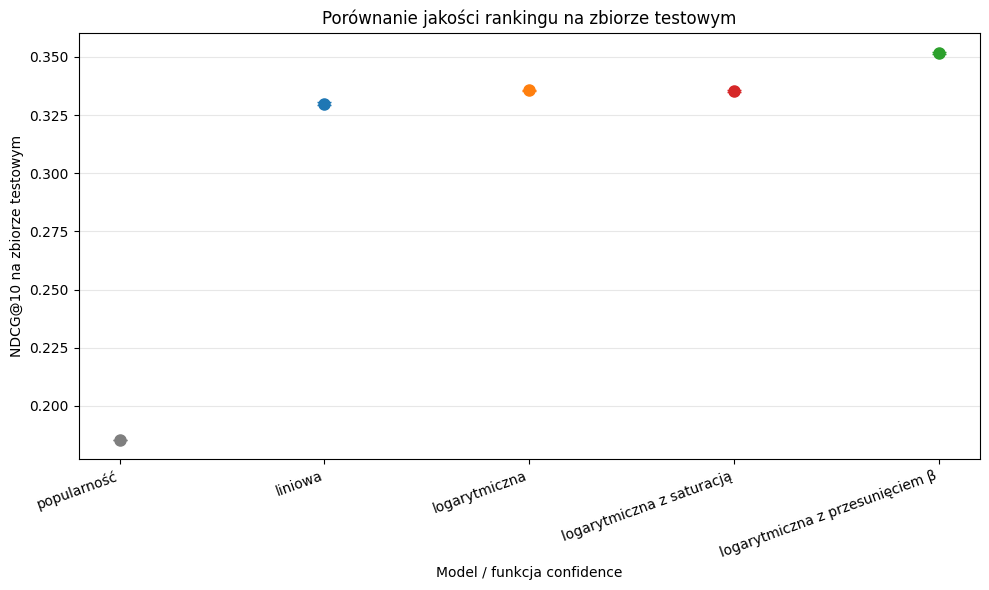

Zapisano: D:\Studiowe\Licencjat\modele\figures\test\test_ndcg_comparison.png


In [5]:
# =========================
# FIGURE 1: TEST NDCG@10 COMPARISON
# =========================

plot_df = test_summary_df.copy()

x = np.arange(len(plot_df))

plt.figure(figsize=(10, 6))

for i, (_, row) in enumerate(plot_df.iterrows()):
    function_name = row["function"]

    y = row[f"ndcg@{K}_mean"]
    yerr = row[f"ndcg@{K}_std"]

    if pd.isna(yerr):
        yerr = 0.0

    plt.errorbar(
        i,
        y,
        yerr=yerr,
        fmt="o",
        capsize=5,
        markersize=8,
        linewidth=1.8,
        color=function_colors.get(function_name, "black"),
    )

plt.xticks(
    x,
    plot_df["function_label"],
    rotation=20,
    ha="right"
)

plt.ylabel(f"NDCG@{K} na zbiorze testowym")
plt.xlabel("Model / funkcja confidence")
plt.title("Porównanie jakości rankingu na zbiorze testowym")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

path = os.path.join(
    test_figures_dir,
    "test_ndcg_comparison.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")

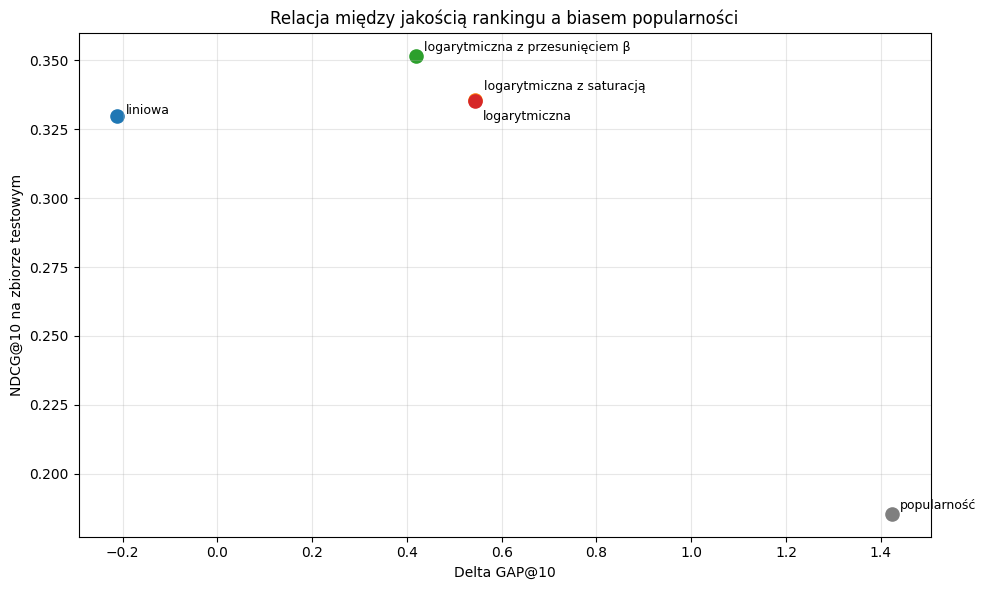

Zapisano: D:\Studiowe\Licencjat\modele\figures\test\test_ndcg_vs_delta_gap.png


In [9]:
# =========================
# FIGURE 2: NDCG vs DELTA GAP
# =========================

plot_df = test_summary_df.copy()

label_offsets = {
    "popular": (6, 6),
    "linear": (6, 4),
    "log": (6, -12),
    "log_saturation": (6, 10),
    "log_inside_beta": (6, 6),
}

plt.figure(figsize=(10, 6))

for _, row in plot_df.iterrows():
    function_name = row["function"]

    x = row[f"delta_gap@{K}_mean"]
    y = row[f"ndcg@{K}_mean"]

    plt.scatter(
        x,
        y,
        s=90,
        color=function_colors.get(function_name, "black"),
    )

    dx, dy = label_offsets.get(function_name, (6, 6))

    plt.annotate(
        row["function_label"],
        (x, y),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="left",
        va="center",
        fontsize=9,
    )

plt.xlabel(f"Delta GAP@{K}")
plt.ylabel(f"NDCG@{K} na zbiorze testowym")
plt.title("Relacja między jakością rankingu a biasem popularności")
plt.grid(True, alpha=0.3)
plt.tight_layout()

path = os.path.join(
    test_figures_dir,
    "test_ndcg_vs_delta_gap.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")

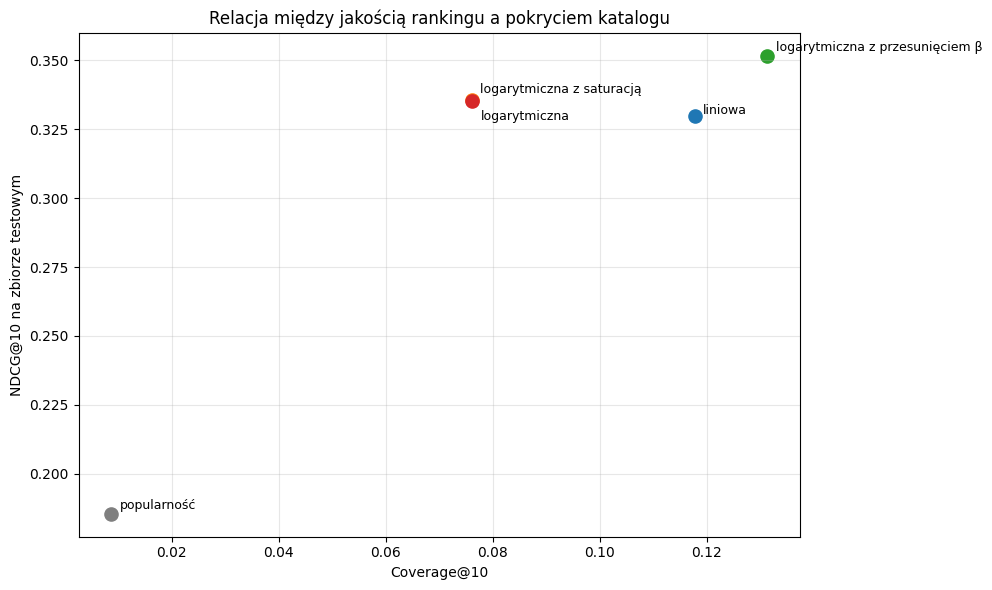

Zapisano: D:\Studiowe\Licencjat\modele\figures\test\test_ndcg_vs_coverage.png


In [8]:
# =========================
# OPTIONAL FIGURE: NDCG vs COVERAGE
# =========================

plot_df = test_summary_df.copy()

label_offsets = {
    "popular": (6, 6),
    "linear": (6, 4),
    "log": (6, -12),
    "log_saturation": (6, 8),
    "log_inside_beta": (6, 6),
}

plt.figure(figsize=(10, 6))

for _, row in plot_df.iterrows():
    function_name = row["function"]

    x = row[f"coverage@{K}_mean"]
    y = row[f"ndcg@{K}_mean"]

    plt.scatter(
        x,
        y,
        s=90,
        color=function_colors.get(function_name, "black"),
        label=row["function_label"],
    )

    dx, dy = label_offsets.get(function_name, (6, 6))

    plt.annotate(
        row["function_label"],
        (x, y),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="left",
        va="center",
        fontsize=9,
    )

plt.xlabel(f"Coverage@{K}")
plt.ylabel(f"NDCG@{K} na zbiorze testowym")
plt.title("Relacja między jakością rankingu a pokryciem katalogu")
plt.grid(True, alpha=0.3)
plt.tight_layout()

path = os.path.join(
    test_figures_dir,
    "test_ndcg_vs_coverage.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")

# new

Loaded files:
D:\Studiowe\Licencjat\modele\final_results\test_metrics_summary_pretty.csv
D:\Studiowe\Licencjat\modele\bpr_results\final\bpr_test_metrics_summary_pretty.csv


,Model,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,popularność,0.0965,0.1783,0.1855,0.0087,1.4233,—,62944
1,liniowa,0.1841 ± 0.0003,0.2642 ± 0.0005,0.3299 ± 0.0005,0.1178 ± 0.0007,-0.2112 ± 0.0016,0.7854 ± 0.0063,62944 ± 0
2,logarytmiczna,0.1810 ± 0.0001,0.3019 ± 0.0002,0.3356 ± 0.0003,0.0762 ± 0.0003,0.5433 ± 0.0008,0.5963 ± 0.0159,62944 ± 0
3,logarytmiczna z saturacją,0.1809 ± 0.0002,0.3019 ± 0.0003,0.3354 ± 0.0005,0.0761 ± 0.0002,0.5443 ± 0.0009,0.5948 ± 0.0152,62944 ± 0
4,logarytmiczna z przesunięciem β,0.1956 ± 0.0002,0.3338 ± 0.0003,0.3517 ± 0.0004,0.1313 ± 0.0009,0.4191 ± 0.0023,0.7314 ± 0.0174,62944 ± 0
5,BPR,0.1329 ± 0.0003,0.2614 ± 0.0005,0.2703 ± 0.0006,0.3039 ± 0.0012,-0.0789 ± 0.0054,0.5499 ± 0.0009,62944 ± 0


,Model,precision@10_mean,precision@10_std,recall@10_mean,recall@10_std,ndcg@10_mean,ndcg@10_std,coverage@10_mean,coverage@10_std,delta_gap@10_mean,delta_gap@10_std,diversity@10_mean,diversity@10_std,users_evaluated_mean,users_evaluated_std
0,popularność,0.0965,NaN,0.1783,NaN,0.1855,NaN,0.0087,NaN,1.4233,NaN,NaN,NaN,62944.0,NaN
1,BPR,0.1329,0.0003,0.2614,0.0005,0.2703,0.0006,0.3039,0.0012,-0.0789,0.0054,0.5499,0.0009,62944.0,0.0
2,liniowa,0.1841,0.0003,0.2642,0.0005,0.3299,0.0005,0.1178,0.0007,-0.2112,0.0016,0.7854,0.0063,62944.0,0.0
3,logarytmiczna,0.1810,0.0001,0.3019,0.0002,0.3356,0.0003,0.0762,0.0003,0.5433,0.0008,0.5963,0.0159,62944.0,0.0
4,logarytmiczna z saturacją,0.1809,0.0002,0.3019,0.0003,0.3354,0.0005,0.0761,0.0002,0.5443,0.0009,0.5948,0.0152,62944.0,0.0
5,logarytmiczna z przesunięciem β,0.1956,0.0002,0.3338,0.0003,0.3517,0.0004,0.1313,0.0009,0.4191,0.0023,0.7314,0.0174,62944.0,0.0


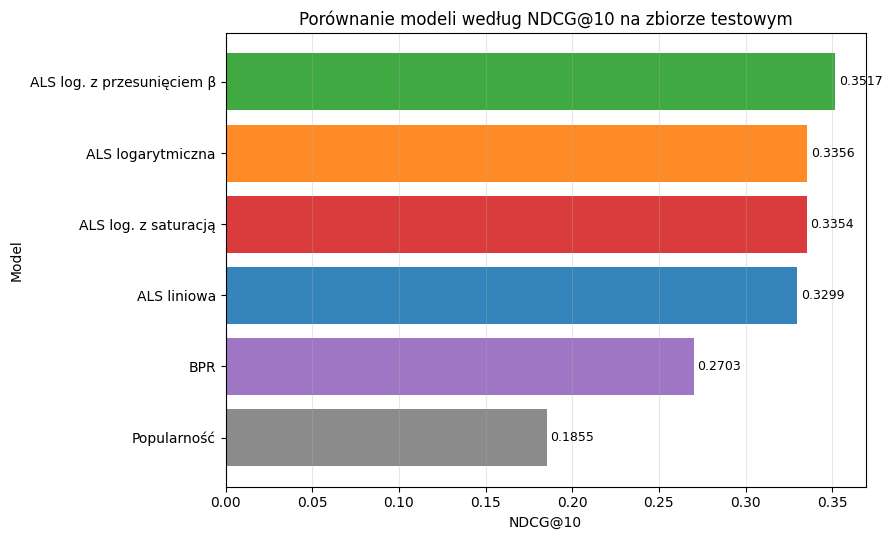

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_ndcg_all_models_horizontal.png


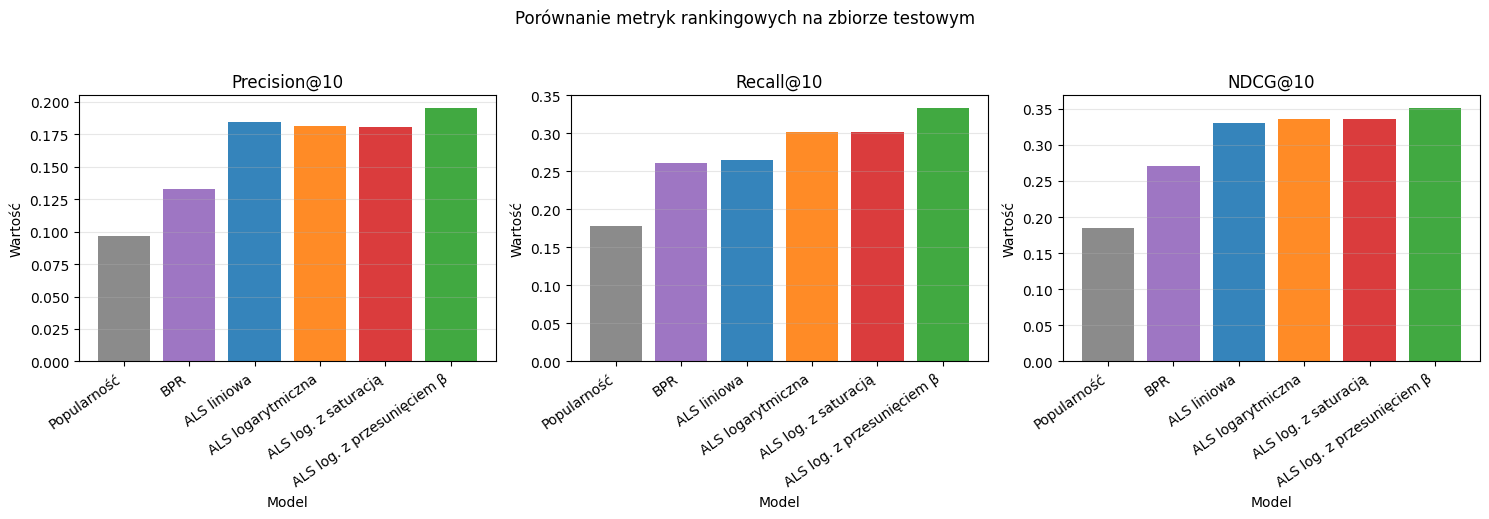

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_ranking_metrics_all_models_panels.png


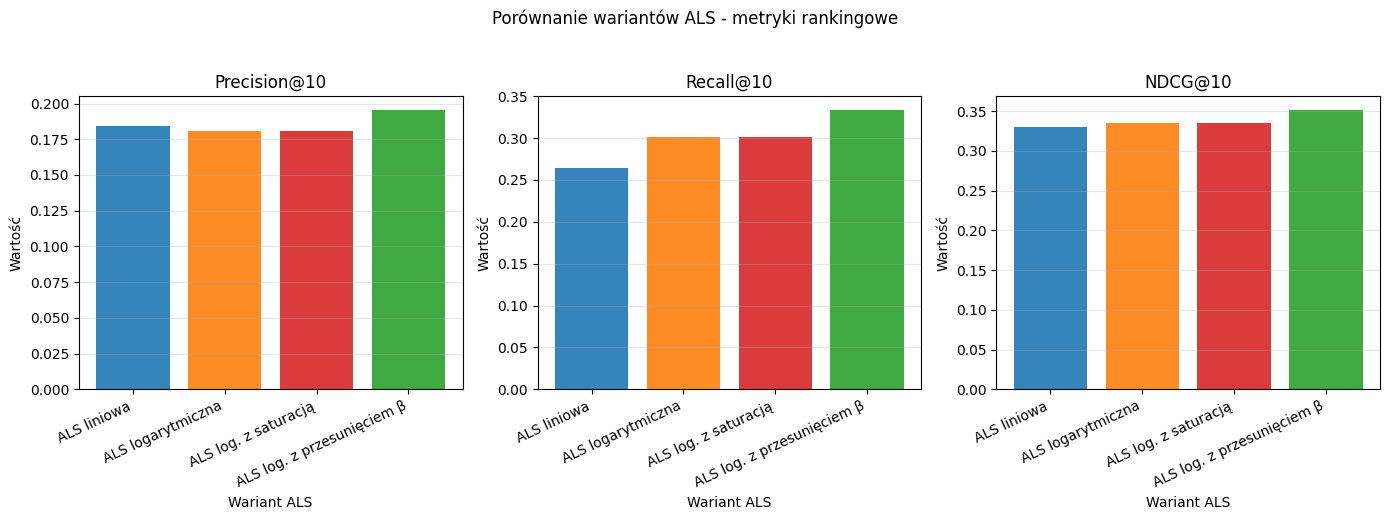

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_ranking_metrics_als_only_panels.png


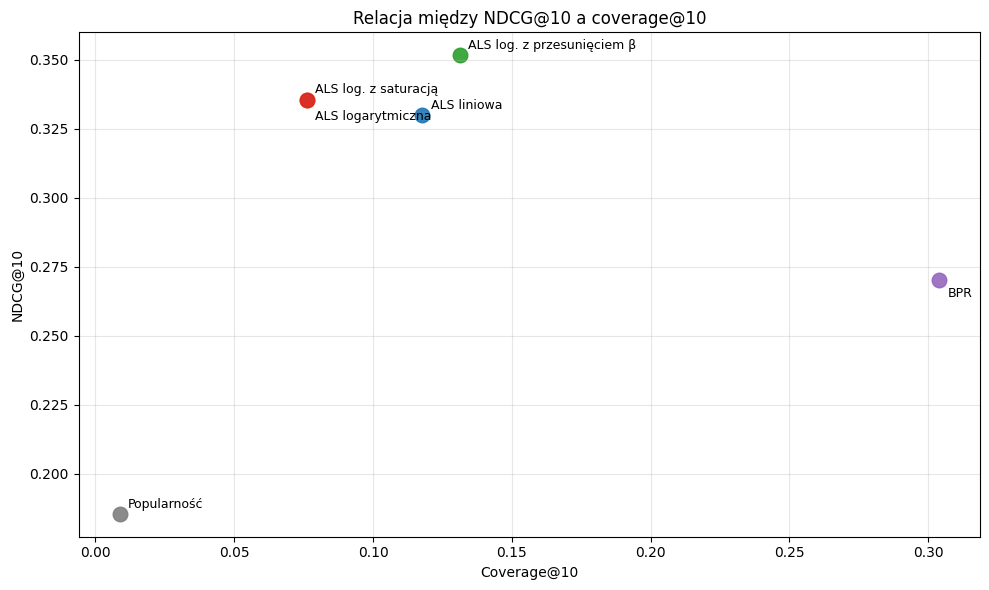

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_ndcg_vs_coverage_all_models.png


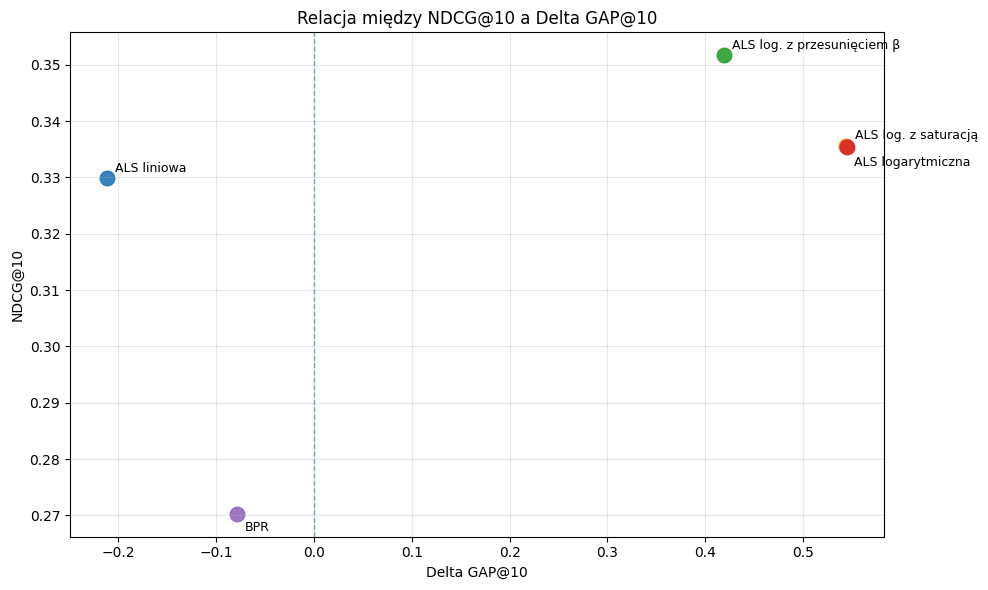

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_ndcg_vs_delta_gap_without_popularity.png


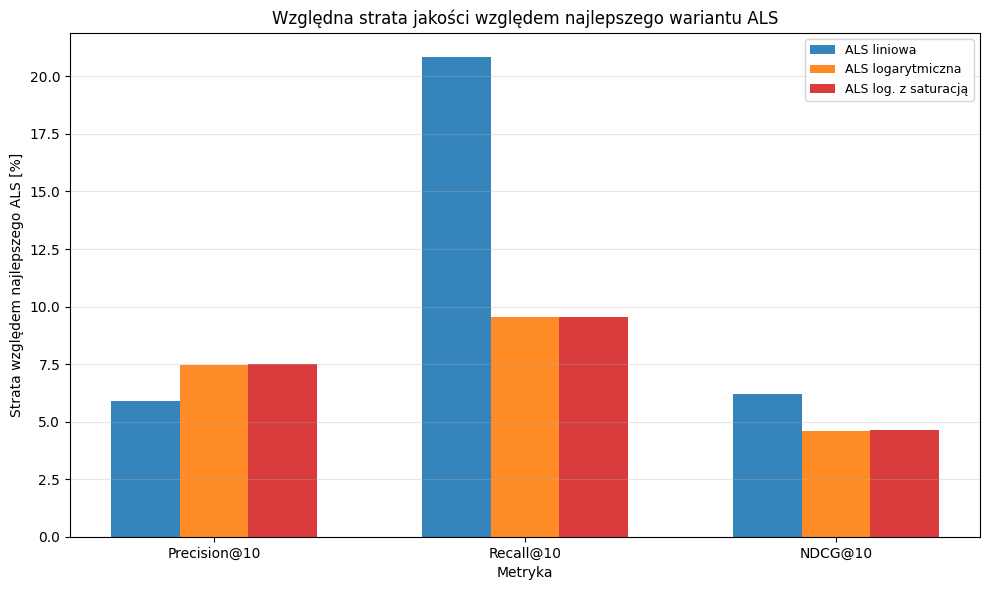

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_als_relative_loss_vs_best_ranking_metrics.png


In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PATHS
# ============================================================

BASE_DIR = Path(str(project_root()))

ALS_RESULTS_PATH = project_path("results/final") / "test_metrics_summary_pretty.csv"
BPR_RESULTS_PATH = project_path("results/bpr") / "final" / "bpr_test_metrics_summary_pretty.csv"

FIGURES_DIR = project_path("results/figures") / "test"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# LOAD DATA
# ============================================================

als_pretty = pd.read_csv(ALS_RESULTS_PATH)
bpr_pretty = pd.read_csv(BPR_RESULTS_PATH)

results_pretty = pd.concat([als_pretty, bpr_pretty], ignore_index=True)

print("Loaded files:")
print(ALS_RESULTS_PATH)
print(BPR_RESULTS_PATH)

display(results_pretty)

# ============================================================
# PARSE "mean ± std"
# ============================================================

metric_cols = [
    "precision@10",
    "recall@10",
    "ndcg@10",
    "coverage@10",
    "delta_gap@10",
    "diversity@10",
    "users_evaluated",
]

def parse_mean_std(value):
    if pd.isna(value):
        return np.nan, np.nan

    value = str(value).strip().replace(",", ".")

    if value in {"", "-", "—"}:
        return np.nan, np.nan

    if "±" in value:
        mean_part, std_part = value.split("±", 1)
        return float(mean_part.strip()), float(std_part.strip())

    return float(value), np.nan


rows = []

for _, row in results_pretty.iterrows():
    parsed_row = {"Model": row["Model"]}

    for metric in metric_cols:
        mean, std = parse_mean_std(row[metric])
        parsed_row[f"{metric}_mean"] = mean
        parsed_row[f"{metric}_std"] = std

    rows.append(parsed_row)

results = pd.DataFrame(rows)

# ============================================================
# ORDER, LABELS, COLORS
# ============================================================

model_order = [
    "popularność",
    "BPR",
    "liniowa",
    "logarytmiczna",
    "logarytmiczna z saturacją",
    "logarytmiczna z przesunięciem β",
]

model_labels = {
    "popularność": "Popularność",
    "BPR": "BPR",
    "liniowa": "ALS liniowa",
    "logarytmiczna": "ALS logarytmiczna",
    "logarytmiczna z saturacją": "ALS log. z saturacją",
    "logarytmiczna z przesunięciem β": "ALS log. z przesunięciem β",
}

model_colors = {
    "popularność": "tab:gray",
    "BPR": "tab:purple",
    "liniowa": "tab:blue",
    "logarytmiczna": "tab:orange",
    "logarytmiczna z saturacją": "tab:red",
    "logarytmiczna z przesunięciem β": "tab:green",
}

results["order"] = results["Model"].map({m: i for i, m in enumerate(model_order)})
results = results.sort_values("order").drop(columns="order").reset_index(drop=True)

display(results)

# ============================================================
# HELPERS
# ============================================================

def save_figure(filename):
    path = FIGURES_DIR / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {path}")

# ============================================================
# FIGURE 1
# NDCG@10 - all models - horizontal bars
# Main figure
# ============================================================

plot_df = results.copy().sort_values("ndcg@10_mean", ascending=True)

models = plot_df["Model"].tolist()
values = plot_df["ndcg@10_mean"].tolist()
y = np.arange(len(models))

plt.figure(figsize=(9, 5.5))

plt.barh(
    y,
    values,
    color=[model_colors.get(m, "gray") for m in models],
    alpha=0.9,
)

plt.yticks(y, [model_labels.get(m, m) for m in models])
plt.xlabel("NDCG@10")
plt.ylabel("Model")
plt.title("Porównanie modeli według NDCG@10 na zbiorze testowym")
plt.grid(axis="x", alpha=0.3)

for i, value in enumerate(values):
    plt.text(
        value + 0.002,
        i,
        f"{value:.4f}",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
save_figure("test_ndcg_all_models_horizontal.png")

# ============================================================
# FIGURE 2
# Precision@10, Recall@10, NDCG@10 - all models
# 3 separate panels, without error bars
# ============================================================

ranking_metrics = ["precision@10", "recall@10", "ndcg@10"]
ranking_metric_labels = ["Precision@10", "Recall@10", "NDCG@10"]

plot_df = results.copy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric, metric_label in zip(axes, ranking_metrics, ranking_metric_labels):
    models = plot_df["Model"].tolist()
    values = plot_df[f"{metric}_mean"].tolist()
    x = np.arange(len(models))

    ax.bar(
        x,
        values,
        color=[model_colors.get(m, "gray") for m in models],
        alpha=0.9,
    )

    ax.set_title(metric_label)
    ax.set_xticks(x)
    ax.set_xticklabels(
        [model_labels.get(m, m) for m in models],
        rotation=35,
        ha="right"
    )
    ax.set_ylabel("Wartość")
    ax.set_xlabel("Model")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Porównanie metryk rankingowych na zbiorze testowym", y=1.03)
plt.tight_layout()
save_figure("test_ranking_metrics_all_models_panels.png")

# ============================================================
# FIGURE 3
# Precision@10, Recall@10, NDCG@10 - ALS only
# Better for showing small differences between ALS variants
# ============================================================

als_models = [
    "liniowa",
    "logarytmiczna",
    "logarytmiczna z saturacją",
    "logarytmiczna z przesunięciem β",
]

plot_df = results[results["Model"].isin(als_models)].copy()

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, metric, metric_label in zip(axes, ranking_metrics, ranking_metric_labels):
    models = plot_df["Model"].tolist()
    values = plot_df[f"{metric}_mean"].tolist()
    x = np.arange(len(models))

    ax.bar(
        x,
        values,
        color=[model_colors.get(m, "gray") for m in models],
        alpha=0.9,
    )

    ax.set_title(metric_label)
    ax.set_xticks(x)
    ax.set_xticklabels(
        [model_labels.get(m, m) for m in models],
        rotation=25,
        ha="right"
    )
    ax.set_ylabel("Wartość")
    ax.set_xlabel("Wariant ALS")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Porównanie wariantów ALS - metryki rankingowe", y=1.03)
plt.tight_layout()
save_figure("test_ranking_metrics_als_only_panels.png")

# ============================================================
# FIGURE 4
# NDCG@10 vs Coverage@10 - all models
# ============================================================

plot_df = results.copy()

label_offsets = {
    "popularność": (6, 7),
    "BPR": (6, -10),
    "liniowa": (6, 7),
    "logarytmiczna": (6, -12),
    "logarytmiczna z saturacją": (6, 8),
    "logarytmiczna z przesunięciem β": (6, 7),
}

plt.figure(figsize=(10, 6))

for _, row in plot_df.iterrows():
    model = row["Model"]
    x_val = row["coverage@10_mean"]
    y_val = row["ndcg@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=model_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        model_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="left",
        va="center",
        fontsize=9,
    )

plt.xlabel("Coverage@10")
plt.ylabel("NDCG@10")
plt.title("Relacja między NDCG@10 a coverage@10")
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("test_ndcg_vs_coverage_all_models.png")

# ============================================================
# FIGURE 5
# NDCG@10 vs Delta GAP@10 - without popularity
# Popularity is too far away and would dominate the plot
# ============================================================

plot_df = results[results["Model"] != "popularność"].copy()

label_offsets = {
    "BPR": (6, -10),
    "liniowa": (6, 7),
    "logarytmiczna": (6, -12),
    "logarytmiczna z saturacją": (6, 8),
    "logarytmiczna z przesunięciem β": (6, 7),
}

plt.figure(figsize=(10, 6))

for _, row in plot_df.iterrows():
    model = row["Model"]
    x_val = row["delta_gap@10_mean"]
    y_val = row["ndcg@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=model_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        model_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="left",
        va="center",
        fontsize=9,
    )

plt.axvline(0, linestyle="--", linewidth=1, alpha=0.6)
plt.xlabel("Delta GAP@10")
plt.ylabel("NDCG@10")
plt.title("Relacja między NDCG@10 a Delta GAP@10")
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("test_ndcg_vs_delta_gap_without_popularity.png")

# ============================================================
# FIGURE 6 - relative loss vs best ALS
# without the best model itself
# ============================================================

plot_df = results[results["Model"].isin(als_models)].copy()

best_model = "logarytmiczna z przesunięciem β"
best_row = plot_df[plot_df["Model"] == best_model].iloc[0]

loss_metrics = ["precision@10", "recall@10", "ndcg@10"]
loss_metric_labels = ["Precision@10", "Recall@10", "NDCG@10"]

for metric in loss_metrics:
    best_value = best_row[f"{metric}_mean"]
    plot_df[f"{metric}_relative_loss_vs_best"] = (
        (best_value - plot_df[f"{metric}_mean"]) / best_value * 100
    )

# usuwamy najlepszy model z wykresu, bo wszędzie ma 0
plot_df = plot_df[plot_df["Model"] != best_model].copy()

x = np.arange(len(loss_metrics))
width = 0.22

plt.figure(figsize=(10, 6))

for i, (_, row) in enumerate(plot_df.iterrows()):
    model = row["Model"]
    losses = [row[f"{metric}_relative_loss_vs_best"] for metric in loss_metrics]
    offset = (i - (len(plot_df) - 1) / 2) * width

    plt.bar(
        x + offset,
        losses,
        width=width,
        label=model_labels.get(model, model),
        color=model_colors.get(model, "gray"),
        alpha=0.9,
    )

plt.xticks(x, loss_metric_labels)
plt.ylabel("Strata względem najlepszego ALS [%]")
plt.xlabel("Metryka")
plt.title("Względna strata jakości względem najlepszego wariantu ALS")
plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()

save_figure("test_als_relative_loss_vs_best_ranking_metrics.png")

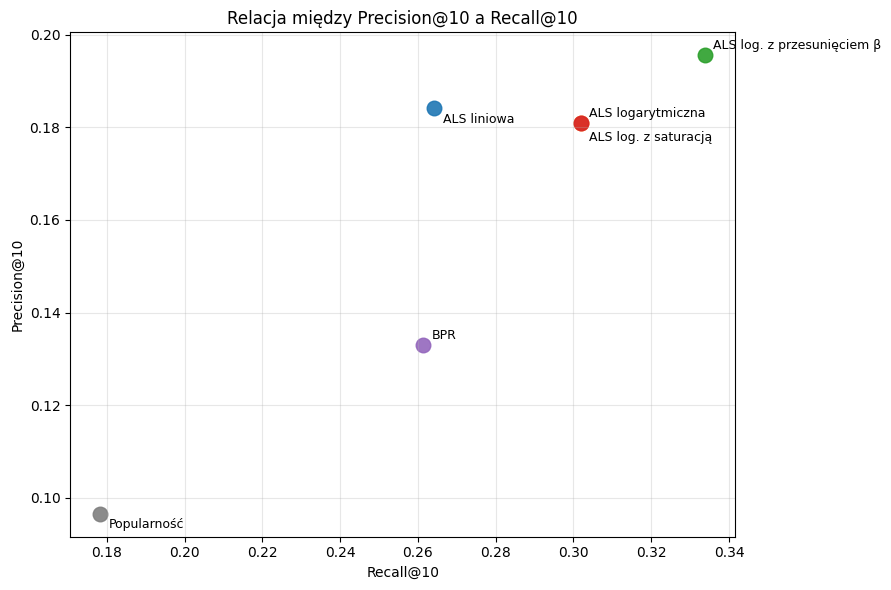

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_precision_vs_recall_all_models.png


In [19]:
# ============================================================
# FIGURE 7
# Precision@10 vs Recall@10 - all models
# ============================================================

plot_df = results.copy()

label_offsets = {
    "popularność": (6, -8),
    "BPR": (6, 7),
    "liniowa": (6, -8),
    "logarytmiczna": (6, 7),
    "logarytmiczna z saturacją": (6, -10),
    "logarytmiczna z przesunięciem β": (6, 7),
}

plt.figure(figsize=(9, 6))

for _, row in plot_df.iterrows():
    model = row["Model"]
    x_val = row["recall@10_mean"]
    y_val = row["precision@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=model_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        model_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="left",
        va="center",
        fontsize=9,
    )

plt.xlabel("Recall@10")
plt.ylabel("Precision@10")
plt.title("Relacja między Precision@10 a Recall@10")
plt.grid(alpha=0.3)
plt.tight_layout()

save_figure("test_precision_vs_recall_all_models.png")

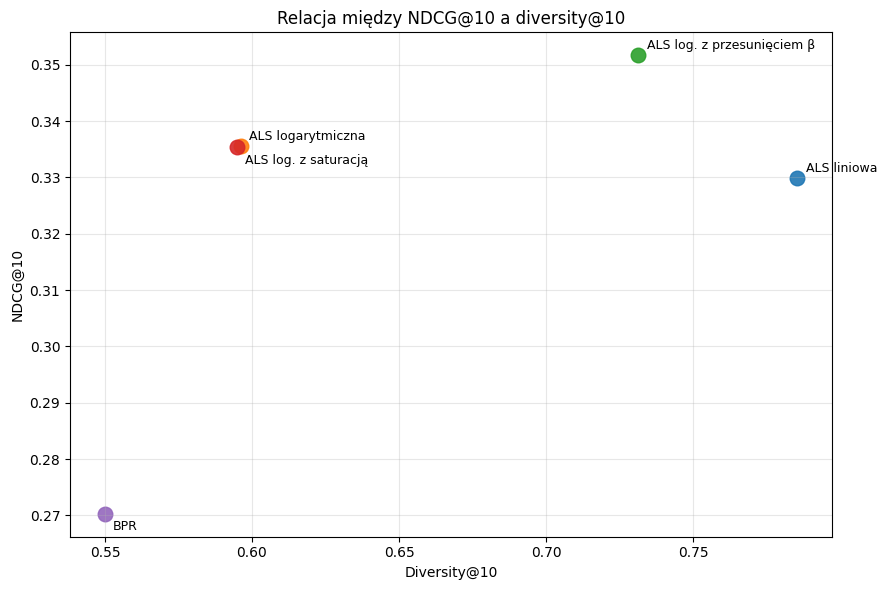

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_ndcg_vs_diversity_without_popularity.png


In [20]:
# ============================================================
# FIGURE 8
# NDCG@10 vs Diversity@10 - without popularity
# ============================================================

plot_df = results[
    (results["Model"] != "popularność")
    & (~results["diversity@10_mean"].isna())
].copy()

label_offsets = {
    "BPR": (6, -9),
    "liniowa": (6, 7),
    "logarytmiczna": (6, 7),
    "logarytmiczna z saturacją": (6, -10),
    "logarytmiczna z przesunięciem β": (6, 7),
}

plt.figure(figsize=(9, 6))

for _, row in plot_df.iterrows():
    model = row["Model"]
    x_val = row["diversity@10_mean"]
    y_val = row["ndcg@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=model_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        model_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="left",
        va="center",
        fontsize=9,
    )

plt.xlabel("Diversity@10")
plt.ylabel("NDCG@10")
plt.title("Relacja między NDCG@10 a diversity@10")
plt.grid(alpha=0.3)
plt.tight_layout()

save_figure("test_ndcg_vs_diversity_without_popularity.png")

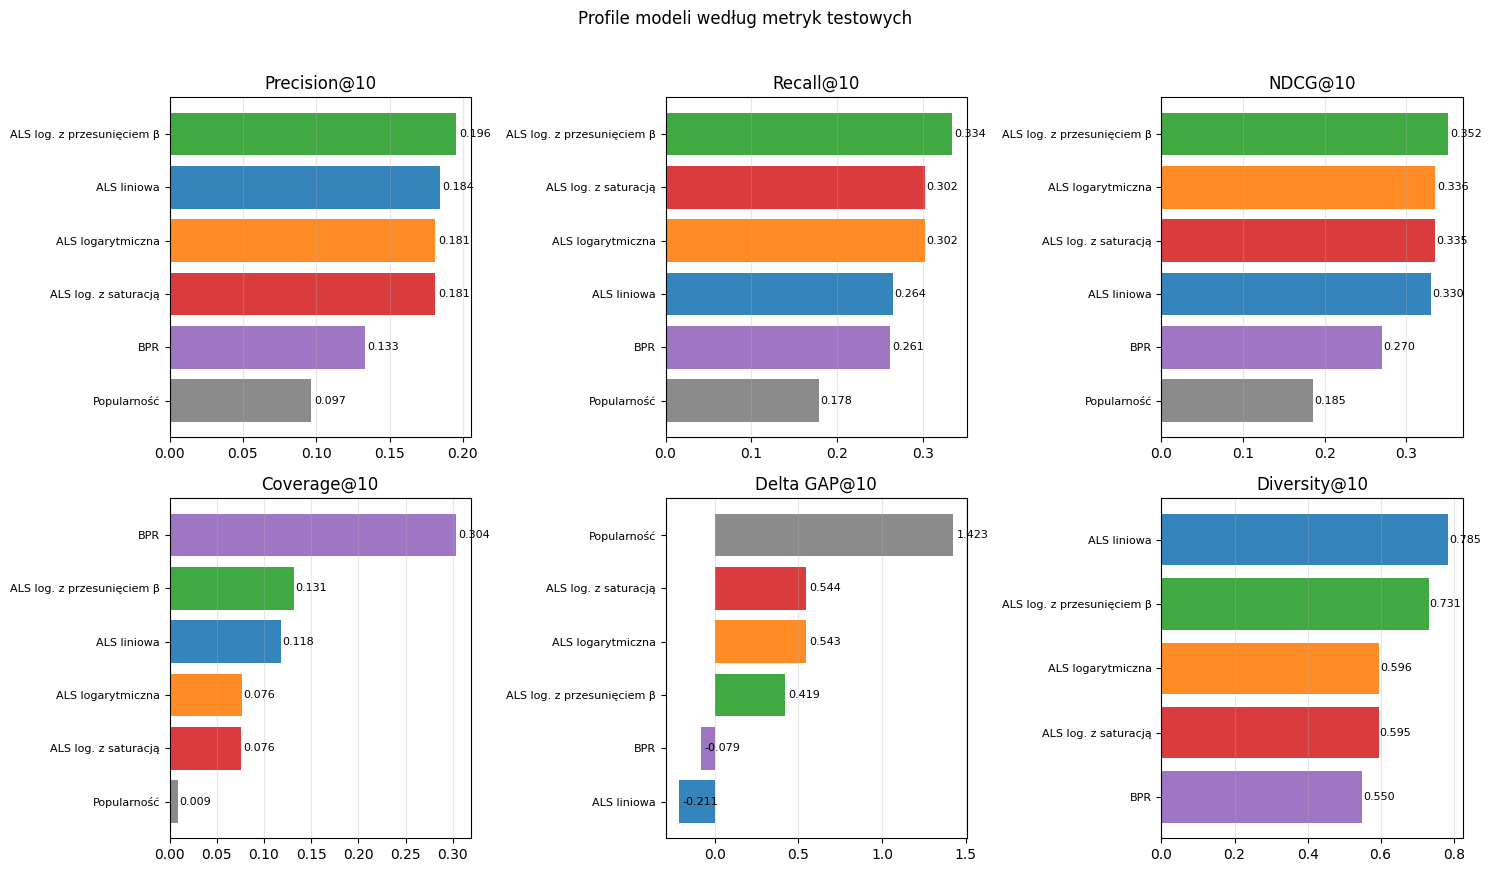

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_model_profiles_small_multiples.png


In [21]:
# ============================================================
# FIGURE 11
# Model profiles - six metrics as small multiples
# ============================================================

profile_metrics = [
    "precision@10",
    "recall@10",
    "ndcg@10",
    "coverage@10",
    "delta_gap@10",
    "diversity@10",
]

profile_metric_labels = [
    "Precision@10",
    "Recall@10",
    "NDCG@10",
    "Coverage@10",
    "Delta GAP@10",
    "Diversity@10",
]

plot_df = results.copy()

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()

for ax, metric, metric_label in zip(axes, profile_metrics, profile_metric_labels):
    metric_df = plot_df.copy()

    if metric == "diversity@10":
        metric_df = metric_df[~metric_df[f"{metric}_mean"].isna()].copy()

    metric_df = metric_df.sort_values(f"{metric}_mean", ascending=True)

    models = metric_df["Model"].tolist()
    values = metric_df[f"{metric}_mean"].tolist()
    y = np.arange(len(models))

    ax.barh(
        y,
        values,
        color=[model_colors.get(m, "gray") for m in models],
        alpha=0.9,
    )

    ax.set_yticks(y)
    ax.set_yticklabels([model_labels.get(m, m) for m in models], fontsize=8)
    ax.set_title(metric_label)
    ax.grid(axis="x", alpha=0.3)

    for i, value in enumerate(values):
        if pd.notna(value):
            offset = 0.002 if metric != "delta_gap@10" else 0.02
            ax.text(
                value + offset,
                i,
                f"{value:.3f}",
                va="center",
                fontsize=8,
            )

fig.suptitle("Profile modeli według metryk testowych", y=1.02)
plt.tight_layout()

save_figure("test_model_profiles_small_multiples.png")

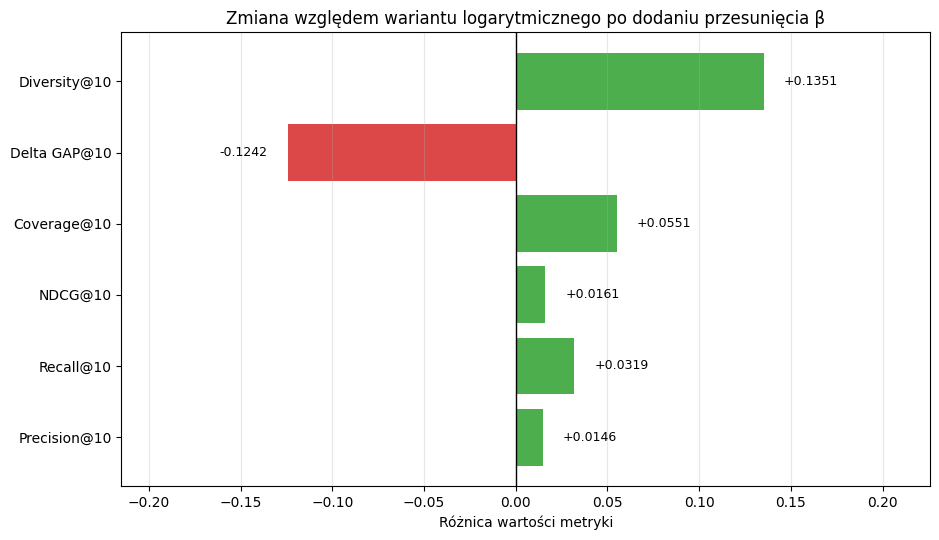

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_log_beta_improvement_over_log.png


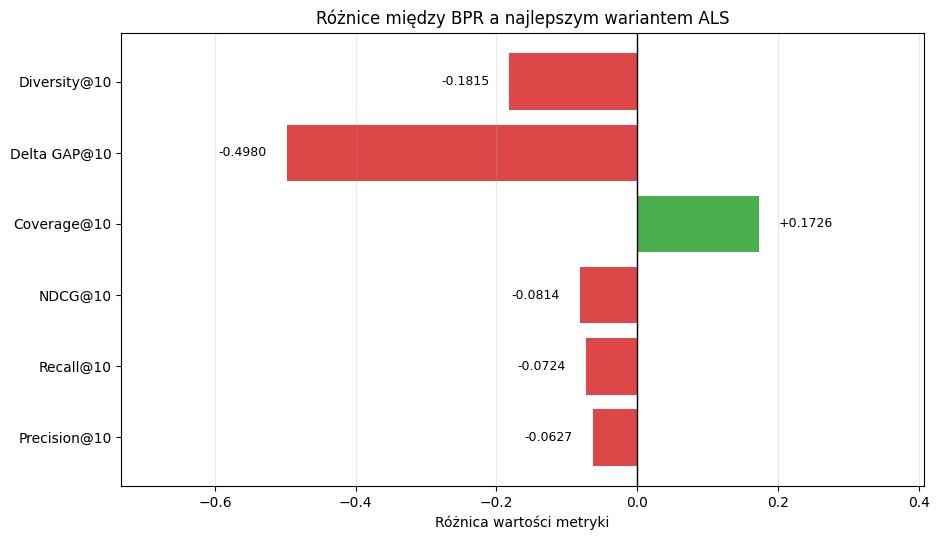

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_bpr_difference_vs_best_als.png


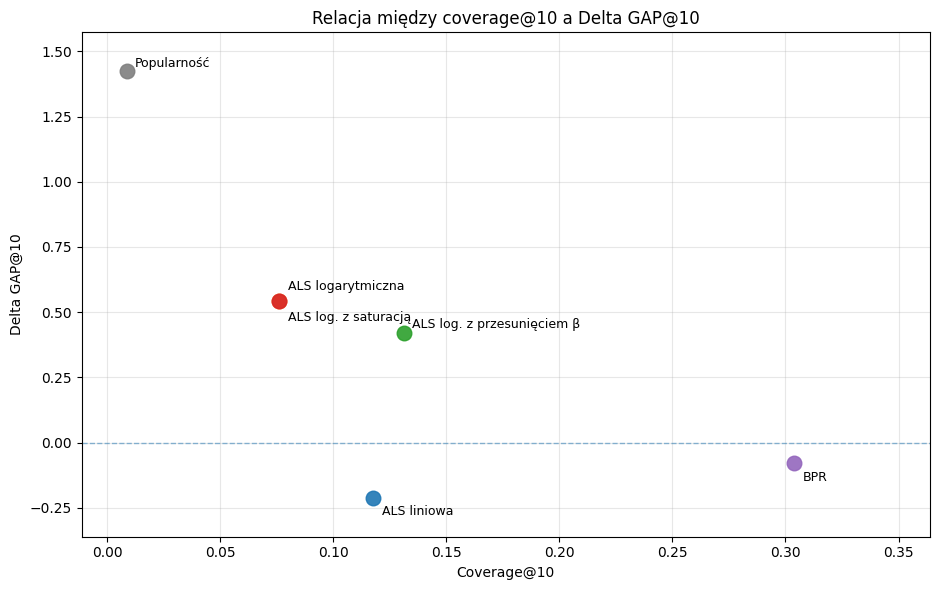

Saved: D:\Studiowe\Licencjat\modele\figures\test\test_coverage_vs_delta_gap_all_models.png


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Helper for difference barplots
# ============================================================

def set_symmetric_xlim_with_padding(values, padding_ratio=0.25):
    values = np.asarray(values, dtype=float)
    min_value = np.nanmin(values)
    max_value = np.nanmax(values)
    
    span = max_value - min_value
    if span == 0:
        span = max(abs(min_value), abs(max_value), 0.01)
    
    padding = span * padding_ratio
    
    plt.xlim(min_value - padding, max_value + padding)


def add_difference_labels(values, y_positions, fontsize=9):
    ax = plt.gca()
    x_min, x_max = ax.get_xlim()
    x_range = x_max - x_min
    offset = 0.025 * x_range
    
    for i, value in zip(y_positions, values):
        if value >= 0:
            text_x = value + offset
            ha = "left"
            
            if text_x > x_max - offset:
                text_x = value - offset
                ha = "right"
        else:
            text_x = value - offset
            ha = "right"
            
            if text_x < x_min + offset:
                text_x = value + offset
                ha = "left"
        
        plt.text(
            text_x,
            i,
            f"{value:+.4f}",
            va="center",
            ha=ha,
            fontsize=fontsize,
        )


# ============================================================
# FIGURE C - improved
# What improves over logarithmic ALS?
# Difference: ALS log with beta - ALS logarithmic
# ============================================================

reference_model = "logarytmiczna"
target_model = "logarytmiczna z przesunięciem β"

comparison_metrics = [
    "precision@10",
    "recall@10",
    "ndcg@10",
    "coverage@10",
    "delta_gap@10",
    "diversity@10",
]

comparison_labels = [
    "Precision@10",
    "Recall@10",
    "NDCG@10",
    "Coverage@10",
    "Delta GAP@10",
    "Diversity@10",
]

ref_row = results[results["Model"] == reference_model].iloc[0]
target_row = results[results["Model"] == target_model].iloc[0]

diff_values = np.array([
    target_row[f"{metric}_mean"] - ref_row[f"{metric}_mean"]
    for metric in comparison_metrics
])

plot_df = pd.DataFrame({
    "metric": comparison_labels,
    "difference": diff_values,
})

plt.figure(figsize=(9.5, 5.5))

colors = [
    "tab:green" if value >= 0 else "tab:red"
    for value in plot_df["difference"]
]

y = np.arange(len(plot_df))

plt.barh(
    y,
    plot_df["difference"],
    color=colors,
    alpha=0.85,
)

plt.axvline(0, color="black", linewidth=1)
plt.yticks(y, plot_df["metric"])
plt.xlabel("Różnica wartości metryki")
plt.title("Zmiana względem wariantu logarytmicznego po dodaniu przesunięcia β")
plt.grid(axis="x", alpha=0.3)

set_symmetric_xlim_with_padding(plot_df["difference"], padding_ratio=0.35)
add_difference_labels(plot_df["difference"], y)

plt.tight_layout()
save_figure("test_log_beta_improvement_over_log.png")

# ============================================================
# FIGURE D - improved
# BPR vs best ALS
# Difference: BPR - ALS log with beta
# ============================================================

reference_model = "logarytmiczna z przesunięciem β"
target_model = "BPR"

comparison_metrics = [
    "precision@10",
    "recall@10",
    "ndcg@10",
    "coverage@10",
    "delta_gap@10",
    "diversity@10",
]

comparison_labels = [
    "Precision@10",
    "Recall@10",
    "NDCG@10",
    "Coverage@10",
    "Delta GAP@10",
    "Diversity@10",
]

ref_row = results[results["Model"] == reference_model].iloc[0]
target_row = results[results["Model"] == target_model].iloc[0]

diff_values = np.array([
    target_row[f"{metric}_mean"] - ref_row[f"{metric}_mean"]
    for metric in comparison_metrics
])

plot_df = pd.DataFrame({
    "metric": comparison_labels,
    "difference": diff_values,
})

plt.figure(figsize=(9.5, 5.5))

colors = [
    "tab:green" if value >= 0 else "tab:red"
    for value in plot_df["difference"]
]

y = np.arange(len(plot_df))

plt.barh(
    y,
    plot_df["difference"],
    color=colors,
    alpha=0.85,
)

plt.axvline(0, color="black", linewidth=1)
plt.yticks(y, plot_df["metric"])
plt.xlabel("Różnica wartości metryki")
plt.title("Różnice między BPR a najlepszym wariantem ALS")
plt.grid(axis="x", alpha=0.3)

set_symmetric_xlim_with_padding(plot_df["difference"], padding_ratio=0.35)
add_difference_labels(plot_df["difference"], y)

plt.tight_layout()
save_figure("test_bpr_difference_vs_best_als.png")

# ============================================================
# FIGURE E - improved
# Coverage@10 vs Delta GAP@10
# Catalog coverage and popularity bias profile
# ============================================================

plot_df = results.copy()

label_offsets = {
    "popularność": (6, 6),
    "BPR": (6, -10),
    "liniowa": (6, -10),
    "logarytmiczna": (6, 10),
    "logarytmiczna z saturacją": (6, -12),
    "logarytmiczna z przesunięciem β": (6, 6),
}

plt.figure(figsize=(9.5, 6))

for _, row in plot_df.iterrows():
    model = row["Model"]

    x_val = row["coverage@10_mean"]
    y_val = row["delta_gap@10_mean"]

    plt.scatter(
        x_val,
        y_val,
        s=110,
        color=model_colors.get(model, "gray"),
        alpha=0.9,
    )

    dx, dy = label_offsets.get(model, (6, 6))

    plt.annotate(
        model_labels.get(model, model),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="left",
        va="center",
        fontsize=9,
    )

plt.axhline(0, linestyle="--", linewidth=1, alpha=0.5)

plt.xlabel("Coverage@10")
plt.ylabel("Delta GAP@10")
plt.title("Relacja między coverage@10 a Delta GAP@10")
plt.grid(alpha=0.3)

# lekkie rozszerzenie osi, żeby etykiety nie były przy brzegu
x_min = plot_df["coverage@10_mean"].min()
x_max = plot_df["coverage@10_mean"].max()
y_min = plot_df["delta_gap@10_mean"].min()
y_max = plot_df["delta_gap@10_mean"].max()

plt.xlim(x_min - 0.02, x_max + 0.06)
plt.ylim(y_min - 0.15, y_max + 0.15)

plt.tight_layout()
save_figure("test_coverage_vs_delta_gap_all_models.png")